# EDA отзывов

Берём [ai-forever/ru-reviews-classification](https://huggingface.co/datasets/ai-forever/ru-reviews-classification): отзывы с метками negative, neutral и positive. Сначала смотрим весь источник, затем очищаем данные и выбираем поровну отзывов каждого класса.

Размер рабочего набора, доли разбиений и seed задаём в `config.yaml`. Исходные train, validation и test сохраняем: общая таблица нужна для анализа и проверки дублей.


## Загружаем и смотрим данные

Работаем с уже скачанными файлами. Версию источника и контрольные суммы берём из `source.json`.


In [1]:
from importlib.metadata import version
from pathlib import Path
import hashlib
import json
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from IPython.display import display

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / 'config.yaml').is_file()
)
config = yaml.safe_load((ROOT / 'config.yaml').read_text(encoding='utf-8'))
settings = config['datasets']['reviews']

SEED = config['seed']
TARGET_SIZE = settings['target_size']
LABELS = settings['label_names']
CLASS_ORDER = list(LABELS.values())
SPLIT_RATIOS = pd.Series(settings['split_ratios'], dtype=float)
SPLITS = list(SPLIT_RATIOS.index)
PREVIEW_SIZE = settings['preview_per_class']
RAW_DIR = ROOT / settings['raw_dir']
PROCESSED_DIR = ROOT / settings['processed_dir']
MANIFEST_DIR = ROOT / settings['manifest_dir']

if TARGET_SIZE <= 0 or TARGET_SIZE % len(LABELS):
    raise ValueError('Размер набора должен делиться на число классов без остатка.')
if not np.isclose(SPLIT_RATIOS.sum(), 1) or (SPLIT_RATIOS <= 0).any():
    raise ValueError('Доли разбиений должны быть положительными и в сумме давать 1.')

pd.set_option('display.max_colwidth', 100)
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

versions = {'Python': platform.python_version()}
versions.update({name: version(name) for name in ['pandas', 'numpy', 'matplotlib', 'seaborn', 'PyYAML']})
display(pd.Series(versions, name='Версия').to_frame())
print('Ядро:', sys.executable)
print('Seed:', SEED)
print('Размер рабочего набора:', TARGET_SIZE)


,Версия
Python,3.14.4
pandas,3.1.1
numpy,2.5.4
matplotlib,3.11.2
seaborn,0.13.2
PyYAML,6.0.3


Ядро: /Users/skyber2/MAI/2_1/frameworks/.venv/bin/python
Seed: 42
Размер рабочего набора: 3000


In [2]:
source = json.loads((RAW_DIR / 'source.json').read_text(encoding='utf-8'))
if source['revision'] != settings['revision']:
    raise ValueError('Версия скачанных данных отличается от версии в конфиге.')

source_files = {item['file']: item for item in source['files']}
frames = []
file_checks = []
for split in SPLITS:
    path = RAW_DIR / f'{split}.jsonl'
    expected = source_files[path.name]
    checksum = hashlib.sha256(path.read_bytes()).hexdigest()
    if checksum != expected['sha256']:
        raise ValueError(f'Изменился исходный файл: {path.name}')

    frame = pd.read_json(path, lines=True, dtype={'id': 'string'})
    if len(frame) != expected['rows']:
        raise ValueError(f'Не совпало число записей в {path.name}.')
    frames.append(frame.assign(split=split))
    file_checks.append({'Файл': path.name, 'Записей': len(frame), 'SHA-256 совпал': True})

df = pd.concat(frames, ignore_index=True)
df['split'] = pd.Categorical(df['split'], categories=SPLITS, ordered=True)

print('Источник:', source['source_url'])
print('Версия:', source['revision'])
print('Лицензия источника:', source['license_declared'])
display(pd.DataFrame(file_checks))


Источник: https://huggingface.co/datasets/ai-forever/ru-reviews-classification
Версия: 0f67d914f396ce22917dc6463ec619799b3b08d2
Лицензия источника: apache-2.0


,Файл,Записей,SHA-256 совпал
0,train.jsonl,45000,True
1,validation.jsonl,15000,True
2,test.jsonl,15000,True


In [3]:
if set(df.columns) != {'id', 'text', 'label', 'label_text', 'split'}:
    raise ValueError('Состав столбцов отличается от ожидаемого.')
if df['id'].dropna().duplicated().any():
    raise ValueError('В источнике повторяются ID, сначала нужно разобраться с ними.')

is_text = df['text'].map(lambda value: isinstance(value, str))
valid_id = (df['id'].notna() & df['id'].str.strip().ne('')).fillna(False)
known_label = df['label'].isin(LABELS)
matching_label = df['label_text'].eq(df['label'].map(LABELS)).fillna(False)
valid_record = (is_text & valid_id & known_label & matching_label).fillna(False)
empty_text = df['text'].str.strip().eq('').fillna(False)

df.info()
display(pd.DataFrame({
    'Тип': df.dtypes.astype(str),
    'Пропуски': df.isna().sum(),
    'Уникальных значений': df.nunique(),
}))
display(pd.Series({
    'Некорректные ID': int((~valid_id).sum()),
    'Текст не является строкой': int((~is_text).sum()),
    'Неизвестные метки': int((~known_label).sum()),
    'Числовая и текстовая метки не совпадают': int((~matching_label).sum()),
    'Пустой текст или только пробелы': int(empty_text.sum()),
}, name='Записей').to_frame())


<class 'pandas.DataFrame'>
RangeIndex: 75000 entries, 0 to 74999
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   text        75000 non-null  str     
 1   label_text  75000 non-null  str     
 2   label       75000 non-null  int64   
 3   id          75000 non-null  string  
 4   split       75000 non-null  category
dtypes: category(1), int64(1), str(2), string(1)
memory usage: 2.4 MB


,Тип,Пропуски,Уникальных значений
text,str,0,75000
label_text,str,0,3
label,int64,0,3
id,string,0,75000
split,category,0,3


,Записей
Некорректные ID,0
Текст не является строкой,0
Неизвестные метки,0
Числовая и текстовая метки не совпадают,0
Пустой текст или только пробелы,1


In [4]:
examples = pd.concat([
    df.loc[df['label'].eq(label)].sample(
        n=min(PREVIEW_SIZE, int(df['label'].eq(label).sum())),
        random_state=SEED,
    )
    for label in LABELS
], ignore_index=True)

with pd.option_context('display.max_colwidth', None):
    display(examples[['id', 'split', 'label_text', 'text']])


,id,split,label_text,text
0,5841,train,negative,"Ужасный просто...широкий...на свой 42 заказала размер S, как-будто размер 48...\nткань вообще не костюмная, весь электризуется, очень тонкий!"
1,24634,test,negative,"Так и не пришел товар! Не успела продлить ожидание, так что и без денег осталась!"
2,11273,train,negative,нифика не хлопок. голимая синтетика. размер подошёл
3,8122,train,negative,Ужасный продавец так и не вернул деньги!!!!!!!!!!!товар так и не пришел ......не рекомендую не кому
4,23980,train,negative,"Продавец открытый хам, пообещал вернуть деньги, хр..н на нэ как говорится, только смайлики с улыбками шлет..."
5,30056,train,neutral,резинка очень тугая перетягивает ногу
6,45994,test,neutral,"Получила заказ в течение месяца, качество нормальное, резинка, все тянется, ношу 48 заказывала xl сел хорошо, но эффект не такой как ожидала, утягивает не очень хорошо, эффект не такой как в описании."
7,41900,train,neutral,длина юбки для моего роста длинова)))
8,49713,train,neutral,"ЦВЕТ КРАСИВЫЙ,ТЕМНО-СИНИЙ,НЕ ТАКОЙ КАК НА ФОТО.ВСЯ ИСКРИТСЯ,СИНТЕТИКА,НУ НЕ ТАК СТРАШНО,ЛАДНО,НА СВОЮ ЦЕНУ ТЯНЕТ,НО РУКАВА В ВЕРХУ У ПЛЕЧА УЗКИЕ.ИЗ-ЗА РУКАВОВ ТЯНЕТ СПЕРЕДИ.ОТДАЛА ДОЧКЕ,У НЕЕ 42Р-Р,ПОДОШЛА"
9,35142,train,neutral,"товар я не получила, но продавец вернул деньги. ставлю три звезды за то, что долго возвращали платеж."


In [5]:
def count_classes(frame):
    counts = pd.crosstab(frame['split'], frame['label_text'])
    return counts.reindex(index=SPLITS, columns=CLASS_ORDER, fill_value=0)


source_counts = count_classes(df)
source_table = source_counts.copy()
source_table['Всего'] = source_table.sum(axis=1)
display(source_table.rename_axis(index='Выборка', columns='Класс'))
print('Всего отзывов:', len(df))


Класс,negative,neutral,positive,Всего
Выборка,,,,
train,15000,15000,15000,45000
validation,5000,5000,5000,15000
test,5000,5000,5000,15000


Всего отзывов: 75000


## Проверяем тексты и убираем лишнее

Оставляем отзывы, в которых есть русские буквы и нет латиницы. Поэтому тексты с латинскими размерами и брендами тоже исключаем. Это отбор по алфавиту: сам по себе он не доказывает, что текст написан на русском.

Для сравнения дублей используем только `strip().lower()`. При разных метках исключаем всю группу. При одинаковых оставляем первую запись в порядке чтения train, validation, test. Сам текст отзыва не меняем.


In [6]:
has_cyrillic = df['text'].str.contains(r'[А-Яа-яЁё]', na=False)
has_latin = df['text'].str.contains(r'[A-Za-z]', na=False)
language_ok = has_cyrillic & ~has_latin

alphabet_groups = pd.Series(np.select(
    [language_ok, has_cyrillic & has_latin, ~has_cyrillic & has_latin],
    ['Русские буквы без латиницы', 'Русские буквы и латиница', 'Латиница без русских букв'],
    default='Нет русских букв и латиницы',
), index=df.index, name='Состав текста')

alphabet_counts = pd.crosstab(alphabet_groups, df['label_text']).reindex(columns=CLASS_ORDER, fill_value=0)
alphabet_counts['Всего'] = alphabet_counts.sum(axis=1)
display(alphabet_counts)

excluded_examples = df.loc[valid_record & ~empty_text & ~language_ok]
with pd.option_context('display.max_colwidth', None):
    display(excluded_examples.sample(
        n=min(PREVIEW_SIZE, len(excluded_examples)), random_state=SEED,
    )[['id', 'label_text', 'text']])


label_text,negative,neutral,positive,Всего
Состав текста,,,,
Латиница без русских букв,340,246,333,919
Нет русских букв и латиницы,6,23,33,62
Русские буквы без латиницы,21910,20943,19728,62581
Русские буквы и латиница,2744,3788,4906,11438


,id,label_text,text
59920,65668,positive,"Ткань больше синтетика, чем хлопок. Тело в нем не дышит. На свой обычный S брала М, село по размеру хорошо. Трек не отслеживается. Доставка 1,5 месяца в Московскую область."
35504,1447,negative,"размер XL мал для размера 46, это ненормально,объем груди 88. шов не должен проходить по центру груди, это неудобно,некомфортно, для этого нужны регулируемые бретели,а они короткие. я разочарована."
5089,3752,negative,Horrible quality. I threw it right away. Really angry about spending my money for this.
25140,72486,positive,УЖЕ В ЧЕТВЕРТЫЙ РАЗ ЗАКАЗЫВАЮ ТАКИЕ ТРУСИКИ. ОНИ ТАКИЕ ПРИЯТНЫЕ К ТЕЛУ.\n\nНА 46 РОС.РАЗМЕР БЕРУ XL/
62094,67426,positive,"Платье просто супер, приятная к телу ткань, качественные пошив, в подарок черный лаковый ремешок, длина на мой рост 164 см, размер L чуть ниже колена"


In [7]:
def split_overlaps(frame):
    keys = {split: set(frame.loc[frame['split'].eq(split), 'text_key']) for split in SPLITS}
    overlaps = pd.DataFrame(0, index=SPLITS, columns=SPLITS)
    for left in SPLITS:
        for right in SPLITS:
            if left != right:
                overlaps.loc[left, right] = len(keys[left] & keys[right])
    return overlaps


df['text_key'] = df['text'].str.strip().str.lower()
duplicate_pool = df.loc[valid_record & ~empty_text]
key_stats = duplicate_pool.groupby('text_key').agg(
    rows=('id', 'size'), labels=('label', 'nunique'), splits=('split', 'nunique'),
)
conflict_keys = key_stats.index[key_stats['labels'] > 1]
source_overlaps = split_overlaps(duplicate_pool)

duplicate_summary = pd.Series({
    'Лишних повторов по ключу текста': int((key_stats['rows'] - 1).sum()),
    'Групп повторяющихся текстов': int((key_stats['rows'] > 1).sum()),
    'Групп с разными метками': len(conflict_keys),
    'Записей в группах с разными метками': int(key_stats.loc[conflict_keys, 'rows'].sum()),
    'Текстов, встречающихся в нескольких разбиениях': int((key_stats['splits'] > 1).sum()),
}, name='Количество')
display(duplicate_summary.to_frame())
print('Общие ключи текста между разбиениями; диагональ не учитываем:')
display(source_overlaps)

conflict_examples = duplicate_pool.loc[
    duplicate_pool['text_key'].isin(conflict_keys[:PREVIEW_SIZE])
].drop_duplicates(['text_key', 'label']).sort_values(['text_key', 'label'])
with pd.option_context('display.max_colwidth', None):
    display(conflict_examples[['id', 'split', 'label_text', 'text']])


,Количество
Лишних повторов по ключу текста,665
Групп повторяющихся текстов,511
Групп с разными метками,152
Записей в группах с разными метками,370
"Текстов, встречающихся в нескольких разбиениях",323


Общие ключи текста между разбиениями; диагональ не учитываем:


,train,validation,test
train,0,170,144
validation,170,0,73
test,144,73,0


,id,split,label_text,text
68351,51277,test,neutral,.
22800,73058,train,positive,.
29653,43482,train,neutral,cool
64886,68387,test,positive,Cool
71124,2310,test,negative,Блузка не пришла
53090,49487,validation,neutral,блузка не пришла
39088,45773,train,neutral,Большие
2810,78910,train,positive,большие
18472,1054,train,negative,большой
3666,37613,train,neutral,большой


In [8]:
reject_reason = pd.Series(pd.NA, index=df.index, dtype='string')
cleaning_rows = [{'Этап': 'Исходный набор', 'Исключено': 0, 'Осталось': len(df)}]
rules = {
    'Некорректные поля': ~valid_record,
    'Пустой текст': empty_text,
    'Не прошли фильтр алфавита': ~language_ok,
    'Одинаковый текст с разными метками': df['text_key'].isin(conflict_keys),
}

for reason, mask in rules.items():
    removed = reject_reason.isna() & mask
    reject_reason.loc[removed] = reason
    cleaning_rows.append({
        'Этап': reason, 'Исключено': int(removed.sum()), 'Осталось': int(reject_reason.isna().sum()),
    })

clean_df = df.loc[reject_reason.isna()].copy()
duplicate_rows = clean_df.duplicated('text_key', keep='first')
reject_reason.loc[clean_df.index[duplicate_rows]] = 'Повторы с одинаковой меткой'
clean_df = clean_df.loc[~duplicate_rows].copy()
cleaning_rows.append({
    'Этап': 'Повторы с одинаковой меткой', 'Исключено': int(duplicate_rows.sum()), 'Осталось': len(clean_df),
})

cleaning_log = pd.DataFrame(cleaning_rows)
display(cleaning_log)
print('Сумма исключений совпала с изменением размера:',
      int(cleaning_log['Исключено'].sum()) == len(df) - len(clean_df))


,Этап,Исключено,Осталось
0,Исходный набор,0,75000
1,Некорректные поля,0,75000
2,Пустой текст,1,74999
3,Не прошли фильтр алфавита,12418,62581
4,Одинаковый текст с разными метками,366,62215
5,Повторы с одинаковой меткой,430,61785


Сумма исключений совпала с изменением размера: True


## Собираем рабочий набор

Выбираем одинаковое число отзывов каждого класса. Доли train, validation и test берём из конфига, принадлежность записей исходным разбиениям сохраняем. Перед случайным отбором сортируем кандидатов по ID, генератор каждый раз создаём с тем же seed.


In [9]:
PER_CLASS = TARGET_SIZE // len(LABELS)
exact_sizes = SPLIT_RATIOS * PER_CLASS
split_sizes = np.floor(exact_sizes).astype(int)
remainder = PER_CLASS - int(split_sizes.sum())
extra_splits = (exact_sizes - split_sizes).sort_values(ascending=False, kind='stable').index[:remainder]
split_sizes.loc[extra_splits] += 1

quotas = pd.DataFrame({name: split_sizes for name in CLASS_ORDER})
available_counts = count_classes(clean_df)
if (available_counts < quotas).any().any():
    raise ValueError('После очистки не хватает отзывов для выбранного размера и долей разбиений.')

rng = np.random.default_rng(SEED)
parts = []
for split in SPLITS:
    for label in LABELS:
        pool = clean_df.loc[clean_df['split'].eq(split) & clean_df['label'].eq(label)].sort_values('id')
        parts.append(pool.sample(n=int(split_sizes[split]), random_state=rng))

working_df = pd.concat(parts, ignore_index=True).sort_values(['split', 'label', 'id']).reset_index(drop=True)
working_counts = count_classes(working_df)
display(working_counts.rename_axis(index='Выборка', columns='Класс'))
print('Всего отзывов:', len(working_df))
print('На каждый класс:', PER_CLASS)


Класс,negative,neutral,positive
Выборка,,,
train,600,600,600
validation,200,200,200
test,200,200,200


Всего отзывов: 3000
На каждый класс: 1000


In [10]:
final_overlaps = split_overlaps(working_df)
class_totals = working_df['label'].value_counts().reindex(LABELS, fill_value=0)
has_text = working_df['text'].str.strip().ne('')
passed_alphabet = (
    working_df['text'].str.contains(r'[А-Яа-яЁё]')
    & ~working_df['text'].str.contains(r'[A-Za-z]')
)
original_rows = df.set_index('id').loc[working_df['id']]
original_columns = ['text', 'label', 'label_text', 'split']
same_original = np.array_equal(
    working_df[original_columns].to_numpy(), original_rows[original_columns].to_numpy(),
)
checks = pd.Series({
    'Размер соответствует конфигу': len(working_df) == TARGET_SIZE,
    'В каждом классе нужное число отзывов': class_totals.eq(PER_CLASS).all(),
    'Квоты классов и разбиений соблюдены': working_counts.eq(quotas).all().all(),
    'Нет пропусков и пустых текстов': working_df.notna().all().all() and has_text.all(),
    'Тексты прошли фильтр алфавита': passed_alphabet.all(),
    'ID не повторяются': working_df['id'].is_unique,
    'Ключи текста не повторяются': working_df['text_key'].is_unique,
    'Нет пересечений между разбиениями': final_overlaps.to_numpy().sum() == 0,
    'Тексты, метки и исходные разбиения сохранены': same_original,
    'Учтены все исключённые строки': int(cleaning_log['Исключено'].sum()) == len(df) - len(clean_df),
}, dtype=bool, name='Пройдена')

display(checks.to_frame())
display(final_overlaps)
if not checks.all():
    raise ValueError('Не пройдены проверки: ' + '; '.join(checks.index[~checks]))


,Пройдена
Размер соответствует конфигу,True
В каждом классе нужное число отзывов,True
Квоты классов и разбиений соблюдены,True
Нет пропусков и пустых текстов,True
Тексты прошли фильтр алфавита,True
ID не повторяются,True
Ключи текста не повторяются,True
Нет пересечений между разбиениями,True
"Тексты, метки и исходные разбиения сохранены",True
Учтены все исключённые строки,True


,train,validation,test
train,0,0,0
validation,0,0,0
test,0,0,0


## Что изменилось после отбора

Сравним размеры и состав трёх наборов. Доли классов показываем на общей шкале: так можно сопоставить исходные данные и небольшую рабочую выборку. Количество исключений считаем по первой сработавшей причине.


,Всего,negative,neutral,positive,"Доля от источника, %"
Этап,,,,,
Исходный,75000,25000,25000,25000,100.00
После очистки,61785,21705,20581,19499,82.38
Рабочий,3000,1000,1000,1000,4.00


,Исходный,После очистки,Рабочий
Выборка,,,
train,45000,37268,1800
validation,15000,12238,600
test,15000,12279,600


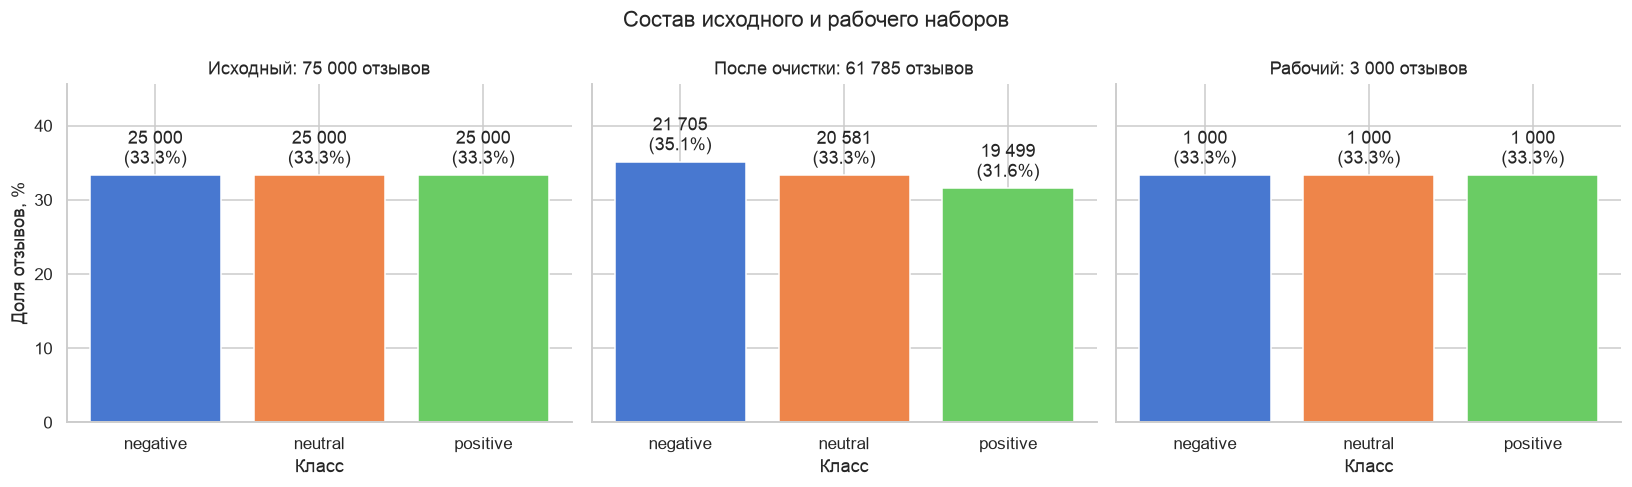

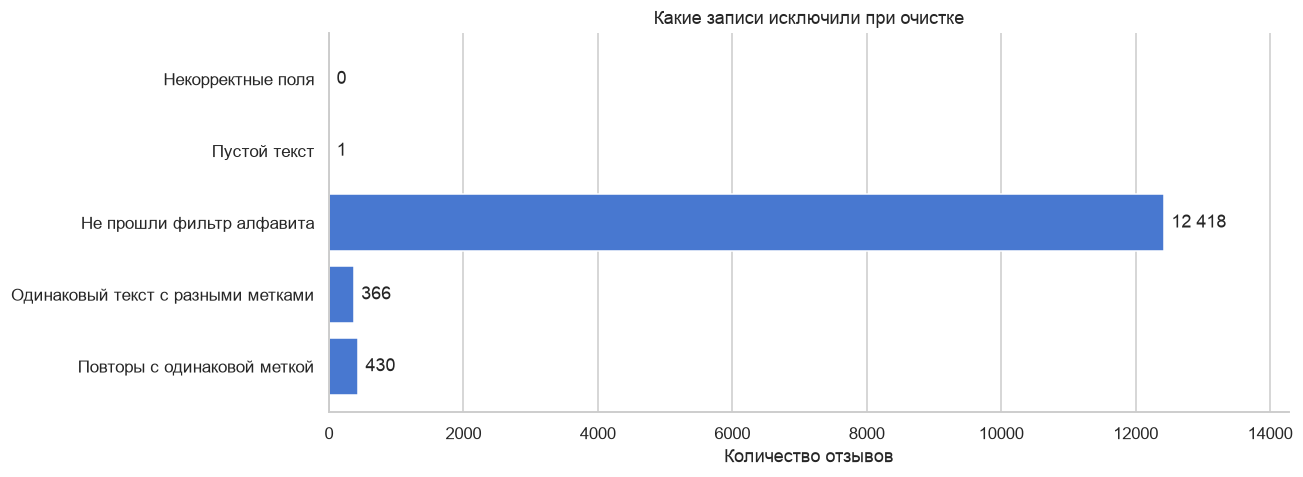

In [11]:
stages = {'Исходный': df, 'После очистки': clean_df, 'Рабочий': working_df}
stage_summary = pd.DataFrame([
    {'Этап': name, 'Всего': len(frame), **frame['label_text'].value_counts().reindex(CLASS_ORDER, fill_value=0).to_dict()}
    for name, frame in stages.items()
]).set_index('Этап')
stage_summary['Доля от источника, %'] = (stage_summary['Всего'] / len(df) * 100).round(2)
split_summary = pd.concat({
    name: frame.groupby('split', observed=True).size().reindex(SPLITS, fill_value=0)
    for name, frame in stages.items()
}, axis=1)
display(stage_summary)
display(split_summary.rename_axis('Выборка'))

class_colors = sns.color_palette('muted', len(CLASS_ORDER))
balance_fig, axes = plt.subplots(1, len(stages), figsize=(15, 4.5), sharey=True)
max_share = max(frame['label_text'].value_counts(normalize=True).max() * 100 for frame in stages.values())
for ax, (name, frame) in zip(axes, stages.items()):
    counts = frame['label_text'].value_counts().reindex(CLASS_ORDER, fill_value=0)
    shares = counts / len(frame) * 100
    bars = ax.bar(CLASS_ORDER, shares, color=class_colors)
    bar_labels = [
        f'{count:,}\n({share:.1f}%)'.replace(',', ' ')
        for count, share in zip(counts, shares)
    ]
    ax.bar_label(bars, labels=bar_labels, padding=4)
    ax.set_title(f'{name}: {len(frame):,} отзывов'.replace(',', ' '))
    ax.set_ylim(0, max_share * 1.3)
    ax.set_xlabel('Класс')
axes[0].set_ylabel('Доля отзывов, %')
balance_fig.suptitle('Состав исходного и рабочего наборов')
balance_fig.tight_layout()
plt.show()

removed_counts = cleaning_log.iloc[1:].set_index('Этап')['Исключено'].iloc[::-1]
removed_fig, ax = plt.subplots(figsize=(12, 4.5))
bars = ax.barh(removed_counts.index, removed_counts.values, color=sns.color_palette('muted')[0])
ax.bar_label(bars, labels=[f'{value:,}'.replace(',', ' ') for value in removed_counts], padding=5)
ax.set_xlim(0, max(1, removed_counts.max()) * 1.15)
ax.set_title('Какие записи исключили при очистке')
ax.set_xlabel('Количество отзывов')
ax.grid(axis='y', visible=False)
removed_fig.tight_layout()
plt.show()



В рабочем наборе классы сбалансированы, каждый отзыв остаётся в своём исходном разбиении. Повторов по выбранному правилу и пересечений между разбиениями нет.

Случайные примеры нужны для знакомства с данными. Все метки вручную пока не проверяли, поэтому смысловые ошибки у уникальных отзывов могут остаться. Отзывы с сочетанием похвалы и критики автоматически не исключаем. ID сохраняем для поиска исходной записи; при обучении он не должен попадать в признаки.


## Сохранение

Сохраняем рабочие train, validation и test и список выбранных ID. Таблицы проверок и графики остаются в выводах ноутбука.


In [12]:
if not checks.all():
    raise ValueError('Сначала нужно пройти проверки рабочего набора.')

for directory in [PROCESSED_DIR, MANIFEST_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

data_columns = ['id', 'text', 'label', 'label_text']
saved_files = []
for split in SPLITS:
    split_data = working_df.loc[working_df['split'].eq(split), data_columns]
    path = PROCESSED_DIR / f'{split}.jsonl'
    split_data.to_json(path, orient='records', lines=True, force_ascii=False)
    saved_files.append({'Файл': str(path.relative_to(ROOT)), 'Отзывов': len(split_data)})

manifest_path = MANIFEST_DIR / 'selected_reviews.csv'
working_df[['id', 'split', 'label', 'label_text']].to_csv(manifest_path, index=False)
display(pd.DataFrame(saved_files))
print('Всего сохранено отзывов:', len(working_df))
print('Список ID:', manifest_path.relative_to(ROOT))


,Файл,Отзывов
0,data/processed/reviews/train.jsonl,1800
1,data/processed/reviews/validation.jsonl,600
2,data/processed/reviews/test.jsonl,600


Всего сохранено отзывов: 3000
Список ID: data/manifests/reviews/selected_reviews.csv
